In [2]:
import nltk

In [3]:
# the following can be of use when identifying tags:
# nltk.help.upenn_tagset()

Let's use the familiar brown corpus to begin with. Get the POS-tagged sentences.

In [32]:
sents = nltk.corpus.brown.tagged_sents() # DONE

# Exercise 1 - Introduction to chunking

## 1a)
Make your own noun phrase (NP) chunker, detecting noun phrases and a clause, for which verbs (VB) are followed by a preposition (IN) and/or a noun phrase.

In [30]:
grammar = r"""
NP: {<DT>?<JJ>*<NN>}
Clause: {<VB.*><IN|NP>}
"""

# TODO: set up a parser using the grammar you defined
chunk_parser = nltk.RegexpParser(grammar)

[('He', 'PPS'), ('is', 'BEZ'), ('not', '*'), ('interested', 'VBN'), ('in', 'IN'), ('being', 'BEG'), ('named', 'VBN'), ('a', 'AT'), ('full-time', 'JJ'), ('director', 'NN')]


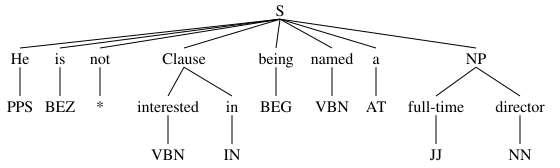

In [33]:
# test your parser!
test_sentence = sents[400][:10]  # just an example sentence, using the first 10 words
chunks = chunk_parser.parse(test_sentence)
chunks

OUTPUT 

![Output](1a.png)

## 1b)
Convert a POS tagged text to a list of tuples, where each tuple consists of a verb followed by a sequence of noun phrases and prepositions.
Example: “the little cat sat on the mat” becomes (‘sat’, ‘on’, ‘NP’) . . . 

In [7]:
def parse_sent(sent):
    return chunk_parser.parse(sent)

def tree_to_tuple(tree):
    lables = []
    for subtree in tree:
        if isinstance(subtree, nltk.Tree):
            lables.append(subtree.label())
        else:
            lables.append(subtree[0])
    
    return tuple(lables)

def chunks_to_verb_NP_tuples(tagged_sents):
    tuples = set()
    """
    iterate the trees and subtrees of your parser.
    add all chunks starting with a verb (CLAUSE) to the set of tuples
    """

    for sent in tagged_sents:
        tree = chunk_parser.parse(sent)
        for subtree in tree.subtrees():
            if subtree.label() == "Clause": tuples.add(tree_to_tuple(subtree))
    
    return list(tuples)

In [8]:
# check your output :-)
import random

vb_np = chunks_to_verb_NP_tuples(sents)
random.shuffle(vb_np)
vb_np[:20]

[('wheeled', 'to'),
 ('leaned', 'with'),
 ('appear', 'above'),
 ("startin'", 'from'),
 ('quotes', 'John'),
 ('Walk', 'by'),
 ('present', 'NP'),
 ('induce', 'NP'),
 ('emerge', 'into'),
 ('receive', 'from'),
 ('abandoning', 'for'),
 ('completed', 'during'),
 ('dismiss', 'NP'),
 ('hanging', 'from'),
 ('acclimatized', 'to'),
 ('mesh', 'with'),
 ('undergone', 'NP'),
 ('outsmarted', 'Washington'),
 ('practice', 'NP'),
 ('proceed', 'with')]

OUTPUT

```
[('fell', 'from'),
 ('raised', 'for'),
 ('disrupted', 'NP'),
 ('look', 'Tilghman'),
 ('bubbling', 'in'),
 ('drive', 'through'),
 ('interfering', 'with'),
 ('wounded', 'Filipino'),
 ('led', 'in'),
 ("crouchin'", 'NP'),
 ('slipped', 'around'),
 ('place', 'on'),
 ('fills', 'with'),
 ('tossed', 'NP'),
 ('governed', 'by'),
 ('bringing', 'NP'),
 ('detected', 'in'),
 ('start', 'NP'),
 ('used', 'Ensolite'),
 ('metabolized', 'by')]
```


## 1c)
Using the pre-annotated test set from wall street journal data (conll2000 in nltk), experiment with different grammars to get the highest possible F-measure. There is no evaluation of this task, but rather a motivator to learn something about grammars.

In [9]:
wsj = nltk.corpus.conll2000
test_sents = wsj.chunked_sents('test.txt', chunk_types=['NP'])

grammar = r"""
NP:{<[CDJNP].*>+}
"""
chunk_parser = nltk.RegexpParser(grammar)
print(chunk_parser.accuracy(test_sents))

ChunkParse score:
    IOB Accuracy:  87.7%%
    Precision:     70.6%%
    Recall:        67.8%%
    F-Measure:     69.2%%


OUTPUT 
```
ChunkParse score:
    IOB Accuracy:  87.7%%
    Precision:     70.6%%
    Recall:        67.8%%
    F-Measure:     69.2%%
```

# Exercise 2 - Making use of chunks

## 2a)
With the following grammar rules:
```
1. proper noun singular
2. determiner followed by an adjective, followed by any noun
3. two consecutive nouns
```
Create a `RegexpParser` chunker

In [10]:
grammar = r"""
Proper: {<NNP>}
Consecutive: {<DT><JJ><NN>}
Nouns: {<NN><NN>}
"""
# TODO: set up a parser using the grammar you defined
chunk_parser = nltk.RegexpParser(grammar)

## 2b)

Read the file `starlink.txt` and perform the following operations on the text:
- sentence tokenize
- word tokenize
- pos tag

In [11]:
import os

"""
TODO:
- read the file "starlink.txt"
- tokenize and tag the words of each sentence

the below function is just an idea of generalization to any file.
you can delete this and write your own code.
"""
# nltk.download('averaged_perceptron_tagger')

def get_pos_tags_from_file(filename):
    sents = open(filename).read()
    sents = nltk.sent_tokenize(sents)
    sents = [nltk.word_tokenize(sent) for sent in sents]
    sents = [nltk.pos_tag(sent) for sent in sents]
    return sents

starlink_tagged = get_pos_tags_from_file("data/starlink.txt")

## 2c)
From all found subtrees in the text, print out the text from all the leaves on the form of `DT -> JJ -> NN` (i.e. the CONSECUTIVE chunk you defined above)

In [12]:
"""
TODO:
write a function to retrieve the DT-JJ-NN sequences
from the grammar you defined in 2a)
"""
def get_descriptive_nouns(tagged_sents):
    descriptive_nouns = []
    for sent in tagged_sents:
        chunked_sent = chunk_parser.parse(sent)
        for subtree in chunked_sent.subtrees():
            if subtree.label() == "Consecutive": descriptive_nouns.append(subtree)

    return descriptive_nouns


for descripive_noun in get_descriptive_nouns(starlink_tagged):
    print(descripive_noun.leaves()[0][0] + " -> " + descripive_noun.leaves()[1][0] + " -> " + descripive_noun.leaves()[2][0])

a -> one-day -> delay
a -> successful -> deployment
a -> classified -> payload
the -> first -> launch
a -> solar -> storm
a -> different -> approach
The -> previous -> launch
a -> single -> burn
the -> upper -> stage
a -> second -> burn
the -> atmospheric -> drag
the -> previous -> set


OUTPUT
```
a -> one-day -> delay
a -> successful -> deployment
a -> classified -> payload
the -> first -> launch
a -> solar -> storm
a -> different -> approach
The -> previous -> launch
a -> single -> burn
the -> upper -> stage
a -> second -> burn
the -> atmospheric -> drag
the -> previous -> set
```


## 2d)
Create a custom rule for a combination of 3 or more tags, similarly to task c).

Do you see any practical uses for chunking with this rule, or in general?

In [13]:
grammar = r"""
Custom: {<JJ.*><JJ.*><NN>}
"""
# TODO: set up a parser using the grammar you defined
chunk_parser = nltk.RegexpParser(grammar)

def get_descriptive_nouns(tagged_sents):
    descriptive_nouns = []
    for sent in tagged_sents:
        chunked_sent = chunk_parser.parse(sent)
        for subtree in chunked_sent.subtrees():
            if subtree.label() == "Custom": descriptive_nouns.append(subtree)

    return descriptive_nouns

for descripive_noun in get_descriptive_nouns(starlink_tagged):
    print(descripive_noun.leaves()[0][0] + " -> " + descripive_noun.leaves()[1][0] + " -> " + descripive_noun.leaves()[2][0])


near -> circular -> orbit


OUTPUT:
```
near -> circular -> orbit
```

To be honest, I think this exact rule wouldn't really have much use. It might be able to compare texts to see which uses the most "filler"/not useful words for their nouns, but this does not really tell us much about the text.

# Exercise 3 - Context-free grammar (CFG)

## 3a)
Create a cfg to handle sentences such as "she is programming", "they are coding" (look at the word forms and POS). The first verb should only handle present tense, while the second verb is flexible. Note that you need to specify the accepted words.

In [14]:
cfg = nltk.CFG.fromstring("""
S -> NP VP
VP -> VB V
NP -> PP
PP -> "she" | "they"
VB -> "is" | "are"
V -> "programming" | "coding"
""")
cfg.productions()

[S -> NP VP,
 VP -> VB V,
 NP -> PP,
 PP -> 'she',
 PP -> 'they',
 VB -> 'is',
 VB -> 'are',
 V -> 'programming',
 V -> 'coding']

OUTPUT
```
[S -> NP VP,
 VP -> VB V,
 NP -> PP,
 PP -> 'she',
 PP -> 'they',
 VB -> 'is',
 VB -> 'are',
 V -> 'programming',
 V -> 'coding']
```

#### A little function to visualize some possible outputs of the grammar
#### Do not change this

In [15]:
def generate_sample(grammar, start, tokens):        
    # iterate left hand and right hand side of the tree
    if start in grammar._lhs_index:
        derivation = random.choice(grammar._lhs_index[start])            
        for rhs in derivation._rhs:          
            generate_sample(grammar, rhs, tokens)
    elif start in grammar._rhs_index:
        tokens.append(str(start))
    return tokens

for _ in range(10):
    print(generate_sample(cfg, cfg.start(), []))

['she', 'is', 'programming']
['they', 'are', 'coding']
['they', 'is', 'coding']
['they', 'is', 'coding']
['they', 'is', 'coding']
['they', 'is', 'coding']
['they', 'are', 'programming']
['she', 'are', 'programming']
['she', 'are', 'programming']
['she', 'are', 'programming']


OUTPUT
```
['they', 'is', 'programming']
['they', 'is', 'coding']
['they', 'is', 'coding']
['she', 'are', 'coding']
['she', 'are', 'coding']
['she', 'is', 'coding']
['they', 'are', 'programming']
['she', 'are', 'coding']
['she', 'is', 'programming']
['she', 'is', 'programming']
```


## 3b)
Find some problems with the above CFG, any ideas how you would improve the results?

I end up with sentences like "she are coding", which is grammatically incorrect. So I could improve the results by making my grammar more strict, and not allow _are_ when the noun is singular. 

## 3c)
Initialize a `ChartParser` with the cfg from 3a).

Write a function to retrieve words not defined by your grammar.

In [16]:
cfg_parser = nltk.ChartParser(cfg) 

def get_missing_words(cfg_grammar, tokens):
    missing = []
    
    for token in tokens:
        if not token in cfg_grammar._lexical_index:
            missing.append(token)

    return missing

Finish the below function

In [17]:
def parse(parser, cfg_grammar, sent):
    tokens = nltk.word_tokenize(sent) # TODO word tokens
    missing = get_missing_words(cfg_grammar, tokens)
    if missing:
        print("Grammar does not cover: {}".format(missing))
        return
    trees = [token for token in parser.parse(tokens)]
    for tree in trees:
        print(tree)
    if len(trees) > 0:
        return trees[0]
    else:
        print("Ungrammatical sentence.")

## 3d)
output the tree of your parser for the sentence "they are programming"

(S (NP (PP they)) (VP (VB are) (V programming)))


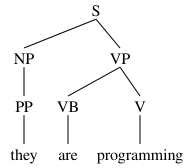

In [18]:
txt = "they are programming"
parse(cfg_parser, cfg, txt)

OUTPUT
```
(S (NP (PP they)) (VP (VB are) (V programming)))
```

![image](3d.png)

# Exercise 4 - Tweet like Trump! Now that he's banned
Using the provided file "realDonaldTrump.json", you will build a language model to generate Trump-esque tweets using n-grams.

Hint: make use of "padded_everygram_pipeline" supported in nltk.lm. This creates all ngrams up to the specified N-parameter with padding:

Example:
```
('<s>',)
('<s>', '<s>')
('<s>', '<s>', '<s>')
('<s>', '<s>', '<s>', '<s>')
('<s>', '<s>', '<s>', '<s>', 'i')
('<s>',)
('<s>', '<s>')
('<s>', '<s>', '<s>')
('<s>', '<s>', '<s>', 'i')
('<s>', '<s>', '<s>', 'i', 'am')
('<s>',)
('<s>', '<s>')
('<s>', '<s>', 'i')
('<s>', '<s>', 'i', 'am')
('<s>', '<s>', 'i', 'am', 'asking')
('<s>',)
('<s>', 'i')
('<s>', 'i', 'am')
('<s>', 'i', 'am', 'asking')
('<s>', 'i', 'am', 'asking', 'for')
('i',)
('i', 'am')
('i', 'am', 'asking')
('i', 'am', 'asking', 'for')
('i', 'am', 'asking', 'for', 'everyone')
```

In [19]:
import json
import pickle
import os
# TODO imports for nltk n-gram modeling and LM
from nltk.lm.preprocessing import padded_everygram_pipeline


Load the JSON data and store the texts:

In [20]:
with open("data/realDonaldTrump.json") as fp:
    tweets = json.load(fp)

texts = list(map(lambda x: x.get("text"), tweets))

In [21]:
# let's use this path to store our model after training, so it's easier to reuse later :)
pickle_path = "model.pkl"

Finish the `train_model` function.

In [22]:
def train_model(data):
    tokenized = [nltk.word_tokenize(sent) for sent in data]  # TODO: use a tokenizer for the twitter data
    print(tokenized)
    n = 3 # TODO find an appropriate N-gram 
    train_data, padded_vocab = padded_everygram_pipeline(n, tokenized) # TODO: padded everygram
    # 
    model = nltk.lm.MLE(n) # TODO: from nltk.lm (language model), use an appropriate estimator
    model.fit(train_data, padded_vocab)
    # save the model if you want to :-) then we can load it in the next step without retraining!
    with open(pickle_path, "wb") as fp:
        pickle.dump(model, fp)
    return model

In [23]:
if os.path.exists(pickle_path):
    with open(pickle_path, "rb") as fp:
        model = pickle.load(fp)
else:
    model = train_model(texts)

In [24]:
def generate_sentence(model, txt):
    txt = nltk.word_tokenize(txt)  # TODO: tokenize the input
    while True:
        next_word = model.generate(text_seed=txt, random_seed=42)
        if next_word == '</s>':
            break
        txt.append(next_word)
        
    def filter_fn(txt):
        no_http = "http" not in txt
        some_other_rule = True
        
        return no_http or some_other_rule
    
    return " ".join([t for t in txt if filter_fn(t)])

In [25]:
print(generate_sentence(model, "some sentence"))
print(generate_sentence(model, "so sad"))
print(generate_sentence(model, "make america great again!"))
print(generate_sentence(model, "hillary clinton"))
print(generate_sentence(model, "obama is"))


some sentence on those that provoke it both ways ” — Fox News guest @ gayletrotter said `` '' YOU 'RE HIRED ! ! '' '' Hello Sal
so sad that lightweight Senator Marco Rubio is polling very poorly in negotiating . China is ordering us to look into the development of my knowledge , leadership
make america great again ! Best show on television is all nothing less than a loudmouth , partisan , political hack who is respected by all accounts has done little to help people get rich easily . Tonight I will bring jobs back to the drive home . See you soon . Can you imagine my saying NO Relief to ......
hillary clinton voted for him in office : https : //t.co/eEDn760Ogh
obama is now officially over ...


OUTPUT
```
some sentence on those that provoke it both ways ” — Fox News guest @ gayletrotter said `` '' YOU 'RE HIRED ! ! '' '' Hello Sal
so sad that lightweight Senator Marco Rubio is polling very poorly in negotiating . China is ordering us to look into the development of my knowledge , leadership
make america great again ! Best show on television is all nothing less than a loudmouth , partisan , political hack who is respected by all accounts has done little to help people get rich easily . Tonight I will bring jobs back to the drive home . See you soon . Can you imagine my saying NO Relief to ......
hillary clinton voted for him in office : https : //t.co/eEDn760Ogh
obama is now officially over ...
```


## 4b)
Create a grammar to chunk some typical trump statements.

There are multiple approaches to this. One way would be to use your own input to the model and look at the resulting outputs and their POS tags. Another possible approach is to use the training data to group together e.g. 5-grams of POS tags to look at the most frequently occurring POS tag groupings. The aim is to have a chunker that groups utterances like "so sad", "make america great again!" and so forth.

Show your results using the outputs from your model with these inputs: 
- "clinton will"
- "obama is"
- "build a"
- "so sad"

In [54]:
trump_grammar = r"""
CHUNK: {<NN>*<JJ><RB>}
        {<NN><VBZ>}
"""

utterences = ["so sad", "make america great again!", "hillary clinton", "obama is", "clinton will", "build a"]

sents = [generate_sentence(model, utter) for utter in utterences]
sents = [nltk.word_tokenize(sent) for sent in sents]
sents = [nltk.pos_tag(sent) for sent in sents]

chunk_parser = nltk.RegexpParser(trump_grammar)
chunks = [print(chunk_parser.parse(sent)) for sent in sents]

(S
  so/RB
  sad/JJ
  that/IN
  lightweight/JJ
  Senator/NNP
  Marco/NNP
  Rubio/NNP
  is/VBZ
  polling/VBG
  very/RB
  poorly/RB
  in/IN
  negotiating/VBG
  ./.
  China/NNP
  is/VBZ
  ordering/VBG
  us/PRP
  to/TO
  look/VB
  into/IN
  the/DT
  development/NN
  of/IN
  my/PRP$
  knowledge/NN
  ,/,
  leadership/NN)
(S
  (CHUNK make/NN america/NN great/JJ again/RB)
  !/.
  Best/JJS
  show/NN
  on/IN
  (CHUNK television/NN is/VBZ)
  all/DT
  nothing/NN
  less/JJR
  than/IN
  a/DT
  loudmouth/NN
  ,/,
  partisan/JJ
  ,/,
  political/JJ
  hack/NN
  who/WP
  is/VBZ
  respected/VBN
  by/IN
  all/DT
  accounts/NNS
  has/VBZ
  done/VBN
  little/JJ
  to/TO
  help/VB
  people/NNS
  get/VB
  (CHUNK rich/JJ easily/RB)
  ./.
  Tonight/NNP
  I/PRP
  will/MD
  bring/VB
  jobs/NNS
  back/RB
  to/TO
  the/DT
  drive/NN
  home/NN
  ./.
  See/VB
  you/PRP
  soon/RB
  ./.
  Can/MD
  you/PRP
  imagine/VB
  my/PRP$
  saying/VBG
  NO/NNP
  Relief/NNP
  to/TO
  ....../VB)
(S
  hillary/JJ
  clinton/NN
  voted/

OUTPUT
```
(S
  so/RB
  sad/JJ
  that/IN
  lightweight/JJ
  Senator/NNP
  Marco/NNP
  Rubio/NNP
  is/VBZ
  polling/VBG
  very/RB
  poorly/RB
  in/IN
  negotiating/VBG
  ./.
  China/NNP
  is/VBZ
  ordering/VBG
  us/PRP
  to/TO
  look/VB
  into/IN
  the/DT
  development/NN
  of/IN
  my/PRP$
  knowledge/NN
  ,/,
  leadership/NN)
(S
  (CHUNK make/NN america/NN great/JJ again/RB)
  !/.
  Best/JJS
  show/NN
  on/IN
  (CHUNK television/NN is/VBZ)
  all/DT
  nothing/NN
  less/JJR
  than/IN
  a/DT
  loudmouth/NN
  ,/,
  partisan/JJ
  ,/,
  political/JJ
  hack/NN
  who/WP
  is/VBZ
  respected/VBN
  by/IN
  all/DT
  accounts/NNS
  has/VBZ
  done/VBN
  little/JJ
  to/TO
  help/VB
  people/NNS
  get/VB
  (CHUNK rich/JJ easily/RB)
  ./.
  Tonight/NNP
  I/PRP
  will/MD
  bring/VB
  jobs/NNS
  back/RB
  to/TO
  the/DT
  drive/NN
  home/NN
  ./.
  See/VB
  you/PRP
  soon/RB
  ./.
  Can/MD
  you/PRP
  imagine/VB
  my/PRP$
  saying/VBG
  NO/NNP
  Relief/NNP
  to/TO
  ....../VB)
(S
  hillary/JJ
  clinton/NN
  voted/VBD
  for/IN
  him/PRP
  in/IN
  office/NN
  :/:
  https/NN
  :/:
  //t.co/eEDn760Ogh/NN)
(S (CHUNK obama/NN is/VBZ) now/RB officially/RB over/IN .../:)
(S
  clinton/NN
  will/MD
  help/VB
  them/PRP
  in/IN
  our/PRP$
  hearts/NNS
  for/IN
  the/DT
  impeachment/JJ
  process—and/NN
  now/RB
  try/VBP
  to/TO
  make/VB
  our/PRP$
  country/NN
  have/VBP
  the/DT
  money/NN
  that/WDT
  is/VBZ
  openly/RB
  defying/VBG
  our/PRP$
  border/NN
  illegally/RB
  ,/,
  think/VBP
  positively/RB
  and/CC
  WIN/NNP
  !/.
  (CHUNK @/NN foxandfriends/VBZ)
  at/IN
  7:30/CD
  AM/NNP
  ./.
  Thank/NNP
  you/PRP
  Joe/NNP
  ./.
  It/PRP
  was/VBD
  my/PRP$
  great/JJ
  honor/NN
  to/TO
  sign/VB
  order/NN
  ,/,
  our/PRP$
  facilities/NNS
  are/VBP
  not/RB
  mutually/RB
  exclusive/JJ
  ./.
  We/PRP
  need/VBP
  someone/NN
  who/WP
  knows/VBZ
  little/JJ
  about…/NN)
(S
  build/VB
  a/DT
  presence/NN
  the/DT
  (CHUNK building/NN gives/VBZ)
  to/TO
  positive/JJ
  women/NNS
  today/NN
  !/.
  Such/JJ
  disrespect/NN
  !/.
  Republicans/NNPS
  are/VBP
  outstripping/VBG
  Democrats/NNPS
  by/IN
  electing/VBG
  @/NNP
  MittRomney/NNP
  is/VBZ
  now/RB
  officially/RB
  over/IN
  .../:)

```
